In [1]:
# CELL 1 - IMPORT LIBRARY DAN KONFIGURASI

from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Menentukan lokasi root repository
cwd = Path.cwd().resolve()

if (cwd / "src" / "data_pipeline.py").exists():
    ROOT = cwd
elif (cwd.parent / "src" / "data_pipeline.py").exists():
    ROOT = cwd.parent
else:
    raise FileNotFoundError(
        "Folder repository tidak ditemukan. "
        "Buka notebook dari folder TheBujangKelompok3."
    )

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.data_pipeline import (
    FEATURES,
    FAULT_TYPES,
    RAW,
    load_dataset
)

%matplotlib inline

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

RANDOM_STATE = 42

print("Root proyek :", ROOT)
print("Dataset     :", RAW)
print("Jumlah fitur:", len(FEATURES))
print("Jumlah kelas:", len(FAULT_TYPES))

Root proyek : C:\Users\LOQ\Documents\TheBujangKelompok3
Dataset     : C:\Users\LOQ\Documents\TheBujangKelompok3\data\raw\faults.csv
Jumlah fitur: 27
Jumlah kelas: 7


### Penjelasan Cell 1 — Import Library dan Konfigurasi

Pada tahap pertama, dilakukan import library yang digunakan untuk Exploratory Data Analysis (EDA) dan preprocessing dataset Steel Plates Faults.

Library yang digunakan meliputi:

- **NumPy:** membantu perhitungan numerik.
- **Pandas:** membaca, memeriksa, dan mengolah dataset.
- **Matplotlib dan Seaborn:** membuat visualisasi data.
- **Scikit-learn:** digunakan untuk pembagian data, imputasi missing value, dan standardisasi.
- **data_pipeline.py:** mengambil daftar fitur dan label yang sebelumnya disiapkan pada proyek kelompok.

Notebook menggunakan struktur fitur yang sama dengan aplikasi web agar pengolahan data tetap konsisten.

Pada tahap ini belum dilakukan pelatihan model Machine Learning.

In [2]:
# CELL 2 - LOAD DATASET STEEL PLATES FAULTS

if not RAW.exists():
    raise FileNotFoundError(
        f"Dataset tidak ditemukan: {RAW}\n"
        "Pastikan faults.csv ada di data/raw/."
    )

df = pd.read_csv(RAW)

# Merapikan nama kolom
df.columns = df.columns.astype(str).str.strip()

# Menangani perbedaan ejaan label
if "K_Scratch" in df.columns and "K_Scatch" not in df.columns:
    df = df.rename(columns={"K_Scratch": "K_Scatch"})

# Mengambil fitur dan target dari pipeline proyek
X, y = load_dataset()

print("DATASET STEEL PLATES FAULTS")
print("=" * 45)
print("Jumlah baris         :", df.shape[0])
print("Jumlah seluruh kolom :", df.shape[1])
print("Jumlah fitur input   :", X.shape[1])
print("Jumlah kolom label   :", len(FAULT_TYPES))
print("Ukuran X             :", X.shape)
print("Ukuran y             :", y.shape)

display(df.head())

DATASET STEEL PLATES FAULTS
Jumlah baris         : 1941
Jumlah seluruh kolom : 34
Jumlah fitur input   : 27
Jumlah kolom label   : 7
Ukuran X             : (1941, 27)
Ukuran y             : (1941,)


,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,Length_of_Conveyer,TypeOfSteel_A300,TypeOfSteel_A400,Steel_Plate_Thickness,Edges_Index,Empty_Index,Square_Index,Outside_X_Index,Edges_X_Index,Edges_Y_Index,Outside_Global_Index,LogOfAreas,Log_X_Index,Log_Y_Index,Orientation_Index,Luminosity_Index,SigmoidOfAreas,Pastry,Z_Scratch,K_Scatch,Stains,Dirtiness,Bumps,Other_Faults
0,42,50,270900,270944,267,17,44,24220,76,108,1687,1,0,80,0.0498,0.2415,0.1818,0.0047,0.4706,1.0000,1.0,2.4265,0.9031,1.6435,0.8182,-0.2913,0.5822,1,0,0,0,0,0,0
1,645,651,2538079,2538108,108,10,30,11397,84,123,1687,1,0,80,0.7647,0.3793,0.2069,0.0036,0.6000,0.9667,1.0,2.0334,0.7782,1.4624,0.7931,-0.1756,0.2984,1,0,0,0,0,0,0
2,829,835,1553913,1553931,71,8,19,7972,99,125,1623,1,0,100,0.9710,0.3426,0.3333,0.0037,0.7500,0.9474,1.0,1.8513,0.7782,1.2553,0.6667,-0.1228,0.2150,1,0,0,0,0,0,0
3,853,860,369370,369415,176,13,45,18996,99,126,1353,0,1,290,0.7287,0.4413,0.1556,0.0052,0.5385,1.0000,1.0,2.2455,0.8451,1.6532,0.8444,-0.1568,0.5212,1,0,0,0,0,0,0
4,1289,1306,498078,498335,2409,60,260,246930,37,126,1353,0,1,185,0.0695,0.4486,0.0662,0.0126,0.2833,0.9885,1.0,3.3818,1.2305,2.4099,0.9338,-0.1992,1.0000,1,0,0,0,0,0,0


### Penjelasan Cell 2 — Load Dataset

Pada tahap ini dilakukan pembacaan dataset Steel Plates Faults menggunakan Pandas.

Dataset ini berisi informasi karakteristik kecacatan pada pelat baja. Dataset standar memiliki 1.941 observasi, 27 fitur input, dan tujuh kolom indikator jenis kecacatan.

Secara keseluruhan, dataset memiliki 34 kolom.

Variabel **X** menyimpan 27 fitur yang nantinya digunakan sebagai masukan model Machine Learning.

Variabel **y** merupakan target berupa salah satu dari tujuh jenis kecacatan.

Hasil pembacaan dataset ditampilkan untuk memastikan file berhasil dimuat dan struktur kolom sesuai dengan kebutuhan proyek.

In [3]:
# CELL 3 - INFORMASI UMUM DATASET

print("INFORMASI DATASET")
print("=" * 50)

df.info()

print("\nLIMA DATA PERTAMA")
display(df.head())

print("\nLIMA DATA TERAKHIR")
display(df.tail())

print("\nSTATISTIK DESKRIPTIF 27 FITUR")
display(X.describe().T.round(3))

print("\nTIPE DATA")
display(df.dtypes.value_counts())

INFORMASI DATASET
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1941 entries, 0 to 1940
Data columns (total 34 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   X_Minimum              1941 non-null   int64  
 1   X_Maximum              1941 non-null   int64  
 2   Y_Minimum              1941 non-null   int64  
 3   Y_Maximum              1941 non-null   int64  
 4   Pixels_Areas           1941 non-null   int64  
 5   X_Perimeter            1941 non-null   int64  
 6   Y_Perimeter            1941 non-null   int64  
 7   Sum_of_Luminosity      1941 non-null   int64  
 8   Minimum_of_Luminosity  1941 non-null   int64  
 9   Maximum_of_Luminosity  1941 non-null   int64  
 10  Length_of_Conveyer     1941 non-null   int64  
 11  TypeOfSteel_A300       1941 non-null   int64  
 12  TypeOfSteel_A400       1941 non-null   int64  
 13  Steel_Plate_Thickness  1941 non-null   int64  
 14  Edges_Index            1941 non-null  

,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,Length_of_Conveyer,TypeOfSteel_A300,TypeOfSteel_A400,Steel_Plate_Thickness,Edges_Index,Empty_Index,Square_Index,Outside_X_Index,Edges_X_Index,Edges_Y_Index,Outside_Global_Index,LogOfAreas,Log_X_Index,Log_Y_Index,Orientation_Index,Luminosity_Index,SigmoidOfAreas,Pastry,Z_Scratch,K_Scatch,Stains,Dirtiness,Bumps,Other_Faults
0,42,50,270900,270944,267,17,44,24220,76,108,1687,1,0,80,0.0498,0.2415,0.1818,0.0047,0.4706,1.0000,1.0,2.4265,0.9031,1.6435,0.8182,-0.2913,0.5822,1,0,0,0,0,0,0
1,645,651,2538079,2538108,108,10,30,11397,84,123,1687,1,0,80,0.7647,0.3793,0.2069,0.0036,0.6000,0.9667,1.0,2.0334,0.7782,1.4624,0.7931,-0.1756,0.2984,1,0,0,0,0,0,0
2,829,835,1553913,1553931,71,8,19,7972,99,125,1623,1,0,100,0.9710,0.3426,0.3333,0.0037,0.7500,0.9474,1.0,1.8513,0.7782,1.2553,0.6667,-0.1228,0.2150,1,0,0,0,0,0,0
3,853,860,369370,369415,176,13,45,18996,99,126,1353,0,1,290,0.7287,0.4413,0.1556,0.0052,0.5385,1.0000,1.0,2.2455,0.8451,1.6532,0.8444,-0.1568,0.5212,1,0,0,0,0,0,0
4,1289,1306,498078,498335,2409,60,260,246930,37,126,1353,0,1,185,0.0695,0.4486,0.0662,0.0126,0.2833,0.9885,1.0,3.3818,1.2305,2.4099,0.9338,-0.1992,1.0000,1,0,0,0,0,0,0



LIMA DATA TERAKHIR


,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,Length_of_Conveyer,TypeOfSteel_A300,TypeOfSteel_A400,Steel_Plate_Thickness,Edges_Index,Empty_Index,Square_Index,Outside_X_Index,Edges_X_Index,Edges_Y_Index,Outside_Global_Index,LogOfAreas,Log_X_Index,Log_Y_Index,Orientation_Index,Luminosity_Index,SigmoidOfAreas,Pastry,Z_Scratch,K_Scatch,Stains,Dirtiness,Bumps,Other_Faults
1936,249,277,325780,325796,273,54,22,35033,119,141,1360,0,1,40,0.3662,0.3906,0.5714,0.0206,0.5185,0.7273,0.0,2.4362,1.4472,1.2041,-0.4286,0.0026,0.7254,0,0,0,0,0,0,1
1937,144,175,340581,340598,287,44,24,34599,112,133,1360,0,1,40,0.2118,0.4554,0.5484,0.0228,0.7046,0.7083,0.0,2.4579,1.4914,1.2305,-0.4516,-0.0582,0.8173,0,0,0,0,0,0,1
1938,145,174,386779,386794,292,40,22,37572,120,140,1360,0,1,40,0.2132,0.3287,0.5172,0.0213,0.7250,0.6818,0.0,2.4654,1.4624,1.1761,-0.4828,0.0052,0.7079,0,0,0,0,0,0,1
1939,137,170,422497,422528,419,97,47,52715,117,140,1360,0,1,40,0.2015,0.5904,0.9394,0.0243,0.3402,0.6596,0.0,2.6222,1.5185,1.4914,-0.0606,-0.0171,0.9919,0,0,0,0,0,0,1
1940,1261,1281,87951,87967,103,26,22,11682,101,133,1360,1,0,80,0.1162,0.6781,0.8000,0.0147,0.7692,0.7273,0.0,2.0128,1.3010,1.2041,-0.2000,-0.1139,0.5296,0,0,0,0,0,0,1



STATISTIK DESKRIPTIF 27 FITUR


,count,mean,std,min,25%,50%,75%,max
X_Minimum,1941.0,571.136,520.691,0.000,51.000,435.000,1053.000,1.705000e+03
X_Maximum,1941.0,617.964,497.627,4.000,192.000,467.000,1072.000,1.713000e+03
Y_Minimum,1941.0,1650684.868,1774578.415,6712.000,471253.000,1204128.000,2183073.000,1.298766e+07
Y_Maximum,1941.0,1650738.705,1774590.089,6724.000,471281.000,1204136.000,2183084.000,1.298769e+07
Pixels_Areas,1941.0,1893.878,5168.460,2.000,84.000,174.000,822.000,1.526550e+05
X_Perimeter,1941.0,111.855,301.209,2.000,15.000,26.000,84.000,1.044900e+04
Y_Perimeter,1941.0,82.966,426.483,1.000,13.000,25.000,83.000,1.815200e+04
Sum_of_Luminosity,1941.0,206312.148,512293.588,250.000,9522.000,19202.000,83011.000,1.159141e+07
Minimum_of_Luminosity,1941.0,84.549,32.134,0.000,63.000,90.000,106.000,2.030000e+02
Maximum_of_Luminosity,1941.0,130.194,18.691,37.000,124.000,127.000,140.000,2.530000e+02



TIPE DATA


int64      21
float64    13
Name: count, dtype: int64

### Penjelasan Cell 3 — Informasi Umum dan Statistik Dataset

Tahap ini bertujuan untuk mengetahui struktur dan karakteristik dataset sebelum dilakukan preprocessing.

Fungsi yang digunakan antara lain:

1. **df.info():** menampilkan informasi tipe data, jumlah kolom, dan nilai yang tidak kosong.
2. **df.head():** menampilkan lima baris pertama dataset.
3. **df.tail():** menampilkan lima baris terakhir dataset.
4. **df.describe():** menampilkan statistik seperti rata-rata, standar deviasi, nilai minimum, maksimum, dan kuartil.

Statistik deskriptif diperlukan untuk memahami rentang nilai dari setiap fitur.

Perbedaan rentang nilai antarfitur dapat memengaruhi algoritma yang menggunakan perhitungan jarak. Oleh karena itu, informasi ini menjadi pertimbangan dalam proses standardisasi data.

In [4]:
# CELL 4 - PEMERIKSAAN MISSING VALUE DAN DUPLIKAT

missing = df.isna().sum()

missing_df = pd.DataFrame({
    "Kolom": df.columns,
    "Missing_Value": missing.values,
    "Persentase_Missing": (
        missing.values / len(df) * 100
    ).round(2)
})

print("PEMERIKSAAN MISSING VALUE")
display(missing_df)

total_missing = int(df.isna().sum().sum())
jumlah_duplikat = int(df.duplicated().sum())

print("\nRINGKASAN KUALITAS DATA")
print("Total missing value :", total_missing)
print("Total baris duplikat:", jumlah_duplikat)

print("\nMISSING VALUE PADA 27 FITUR")
display(X.isna().sum().to_frame("Jumlah Missing"))

print("\nSTATUS DATA")

if total_missing == 0:
    print("Tidak ditemukan missing value pada dataset asli.")
else:
    print("Terdapat missing value yang perlu ditangani.")

if jumlah_duplikat == 0:
    print("Tidak ditemukan baris duplikat.")
else:
    print("Terdapat baris duplikat yang perlu diperiksa.")

PEMERIKSAAN MISSING VALUE


,Kolom,Missing_Value,Persentase_Missing
0,X_Minimum,0,0.0
1,X_Maximum,0,0.0
2,Y_Minimum,0,0.0
3,Y_Maximum,0,0.0
4,Pixels_Areas,0,0.0
5,X_Perimeter,0,0.0
6,Y_Perimeter,0,0.0
7,Sum_of_Luminosity,0,0.0
8,Minimum_of_Luminosity,0,0.0
9,Maximum_of_Luminosity,0,0.0



RINGKASAN KUALITAS DATA
Total missing value : 0
Total baris duplikat: 0

MISSING VALUE PADA 27 FITUR


,Jumlah Missing
X_Minimum,0
X_Maximum,0
Y_Minimum,0
Y_Maximum,0
Pixels_Areas,0
X_Perimeter,0
Y_Perimeter,0
Sum_of_Luminosity,0
Minimum_of_Luminosity,0
Maximum_of_Luminosity,0



STATUS DATA
Tidak ditemukan missing value pada dataset asli.
Tidak ditemukan baris duplikat.


### Penjelasan Cell 4 — Pemeriksaan Kualitas Data

Pada tahap ini dilakukan pemeriksaan missing value dan data duplikat.

**Missing value** merupakan nilai yang kosong atau tidak tersedia pada suatu kolom. Kondisi tersebut dapat mengganggu pengolahan data apabila tidak ditangani.

**Data duplikat** adalah baris data yang memiliki isi sama dengan baris lainnya. Keberadaan data duplikat perlu diperiksa karena dapat memengaruhi hasil analisis.

Pemeriksaan dilakukan sebelum preprocessing untuk mengetahui kondisi awal dataset.

Jika terdapat missing value, salah satu metode penanganannya adalah imputasi median. Namun, proses imputasi untuk pelatihan supervised learning harus dilakukan menggunakan data training agar tidak terjadi data leakage.

Jumlah missing value dan data duplikat mengikuti hasil yang ditampilkan notebook.

In [5]:
# CELL 5 - PEMISAHAN FITUR DAN LABEL

print("DAFTAR 27 FITUR INPUT")

for nomor, fitur in enumerate(FEATURES, start=1):
    print(f"{nomor:2}. {fitur}")

print("\nDAFTAR 7 JENIS CACAT")

for nomor, label in enumerate(FAULT_TYPES, start=1):
    print(f"{nomor}. {label}")

# Mengambil kolom indikator kelas
label_columns = df[FAULT_TYPES].copy()

# Setiap baris harus memiliki tepat satu label aktif
valid_labels = (
    label_columns.isin([0, 1]).all(axis=1)
    & (label_columns.sum(axis=1) == 1)
)

print("\nVALIDASI LABEL")
print("Baris valid      :", int(valid_labels.sum()))
print("Baris tidak valid:", int((~valid_labels).sum()))

assert X.shape[1] == 27
assert len(FAULT_TYPES) == 7
assert valid_labels.all()
assert set(X.columns).isdisjoint(FAULT_TYPES)

print("\nCONTOH FITUR")
display(X.head())

print("\nCONTOH TARGET")
display(y.head().to_frame(name="Fault_Type"))

DAFTAR 27 FITUR INPUT
 1. X_Minimum
 2. X_Maximum
 3. Y_Minimum
 4. Y_Maximum
 5. Pixels_Areas
 6. X_Perimeter
 7. Y_Perimeter
 8. Sum_of_Luminosity
 9. Minimum_of_Luminosity
10. Maximum_of_Luminosity
11. Length_of_Conveyer
12. TypeOfSteel_A300
13. TypeOfSteel_A400
14. Steel_Plate_Thickness
15. Edges_Index
16. Empty_Index
17. Square_Index
18. Outside_X_Index
19. Edges_X_Index
20. Edges_Y_Index
21. Outside_Global_Index
22. LogOfAreas
23. Log_X_Index
24. Log_Y_Index
25. Orientation_Index
26. Luminosity_Index
27. SigmoidOfAreas

DAFTAR 7 JENIS CACAT
1. Pastry
2. Z_Scratch
3. K_Scatch
4. Stains
5. Dirtiness
6. Bumps
7. Other_Faults

VALIDASI LABEL
Baris valid      : 1941
Baris tidak valid: 0

CONTOH FITUR


,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,Length_of_Conveyer,TypeOfSteel_A300,TypeOfSteel_A400,Steel_Plate_Thickness,Edges_Index,Empty_Index,Square_Index,Outside_X_Index,Edges_X_Index,Edges_Y_Index,Outside_Global_Index,LogOfAreas,Log_X_Index,Log_Y_Index,Orientation_Index,Luminosity_Index,SigmoidOfAreas
0,42,50,270900,270944,267,17,44,24220,76,108,1687,1,0,80,0.0498,0.2415,0.1818,0.0047,0.4706,1.0000,1.0,2.4265,0.9031,1.6435,0.8182,-0.2913,0.5822
1,645,651,2538079,2538108,108,10,30,11397,84,123,1687,1,0,80,0.7647,0.3793,0.2069,0.0036,0.6000,0.9667,1.0,2.0334,0.7782,1.4624,0.7931,-0.1756,0.2984
2,829,835,1553913,1553931,71,8,19,7972,99,125,1623,1,0,100,0.9710,0.3426,0.3333,0.0037,0.7500,0.9474,1.0,1.8513,0.7782,1.2553,0.6667,-0.1228,0.2150
3,853,860,369370,369415,176,13,45,18996,99,126,1353,0,1,290,0.7287,0.4413,0.1556,0.0052,0.5385,1.0000,1.0,2.2455,0.8451,1.6532,0.8444,-0.1568,0.5212
4,1289,1306,498078,498335,2409,60,260,246930,37,126,1353,0,1,185,0.0695,0.4486,0.0662,0.0126,0.2833,0.9885,1.0,3.3818,1.2305,2.4099,0.9338,-0.1992,1.0000



CONTOH TARGET


,Fault_Type
0,Pastry
1,Pastry
2,Pastry
3,Pastry
4,Pastry


### Penjelasan Cell 5 — Pemisahan Fitur dan Label

Dataset Steel Plates Faults memiliki 27 fitur input dan tujuh kolom indikator jenis kecacatan.

Tujuh kategori kecacatan yang terdapat pada dataset adalah:

1. **Pastry:** salah satu jenis cacat permukaan pelat baja.
2. **Z_Scratch:** kategori cacat berupa goresan.
3. **K_Scatch:** kategori goresan lain yang berbeda dari Z_Scratch, mengikuti nama pada dataset.
4. **Stains:** cacat yang ditandai dengan noda pada permukaan.
5. **Dirtiness:** cacat yang berkaitan dengan kotoran.
6. **Bumps:** cacat berupa tonjolan atau ketidakrataan.
7. **Other_Faults:** jenis kecacatan lain yang tidak termasuk keenam kategori sebelumnya.

Dataset menggunakan tujuh kolom indikator bernilai 0 atau 1. Nilai 1 menunjukkan kategori cacat yang aktif pada sebuah observasi.

Ketujuh kolom tersebut diubah menjadi satu target bernama Fault_Type melalui fungsi load_dataset().

Pemisahan fitur dan label bertujuan mencegah **target leakage**, yaitu ketika informasi target ikut dimasukkan sebagai fitur input.

Pada supervised learning, 27 fitur digunakan untuk memprediksi jenis cacat. Pada unsupervised learning, proses clustering menggunakan fitur tanpa memasukkan label.

DISTRIBUSI TUJUH JENIS CACAT


,Jenis_Cacat,Jumlah_Data,Persentase
0,Pastry,158,8.14
1,Z_Scratch,190,9.79
2,K_Scatch,391,20.14
3,Stains,72,3.71
4,Dirtiness,55,2.83
5,Bumps,402,20.71
6,Other_Faults,673,34.67


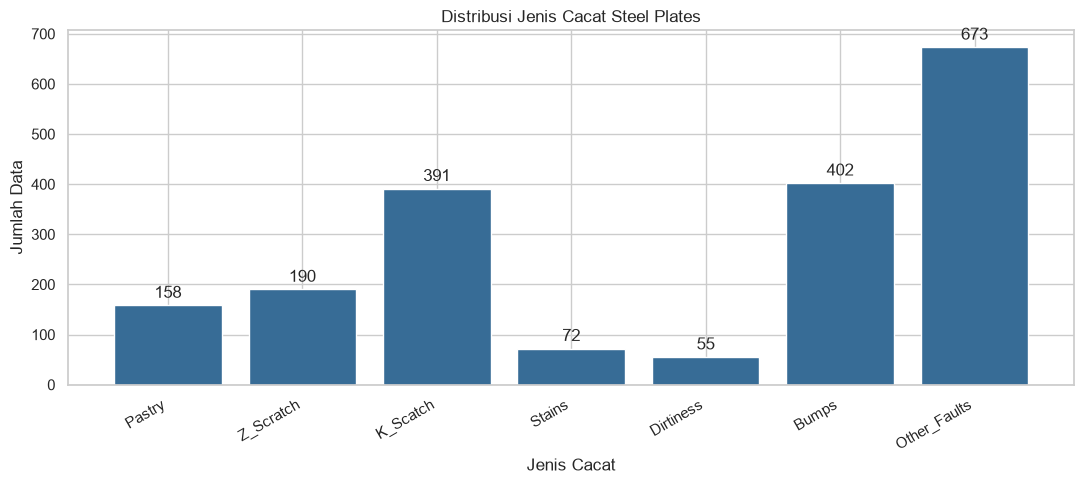

In [6]:
# CELL 6 - DISTRIBUSI TUJUH JENIS CACAT

class_counts = y.value_counts().reindex(
    FAULT_TYPES,
    fill_value=0
)

class_percent = (
    class_counts / len(y) * 100
).round(2)

distribusi_df = pd.DataFrame({
    "Jenis_Cacat": class_counts.index,
    "Jumlah_Data": class_counts.values,
    "Persentase": class_percent.values
})

print("DISTRIBUSI TUJUH JENIS CACAT")
display(distribusi_df)

fig, ax = plt.subplots(figsize=(11, 5))

bars = ax.bar(
    class_counts.index,
    class_counts.values,
    color="#376c96"
)

ax.bar_label(bars, padding=3)

ax.set_title("Distribusi Jenis Cacat Steel Plates")
ax.set_xlabel("Jenis Cacat")
ax.set_ylabel("Jumlah Data")

plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### Penjelasan Cell 6 — Distribusi Jenis Cacat

Visualisasi ini bertujuan mengetahui jumlah data pada masing-masing kategori kecacatan pelat baja.

Grafik batang memperlihatkan perbandingan jumlah observasi pada tujuh kelas.

Melalui visualisasi tersebut, dapat diketahui apakah distribusi kelas seimbang atau terdapat kelas dengan jumlah data jauh lebih banyak dibandingkan kelas lain.

Kondisi ketika jumlah observasi antar kelas tidak seimbang disebut **class imbalance**.

Class imbalance penting diperhatikan karena model supervised learning dapat lebih mudah mengenali kelas dengan jumlah data besar dibandingkan kelas yang jumlahnya sedikit.

Oleh sebab itu, Orang 3 perlu menggunakan metrik seperti precision, recall, dan macro F1-score dalam mengevaluasi model klasifikasi, bukan hanya accuracy.

FITUR YANG DIVISUALISASIKAN
['Pixels_Areas', 'Steel_Plate_Thickness', 'Edges_Index', 'Luminosity_Index']


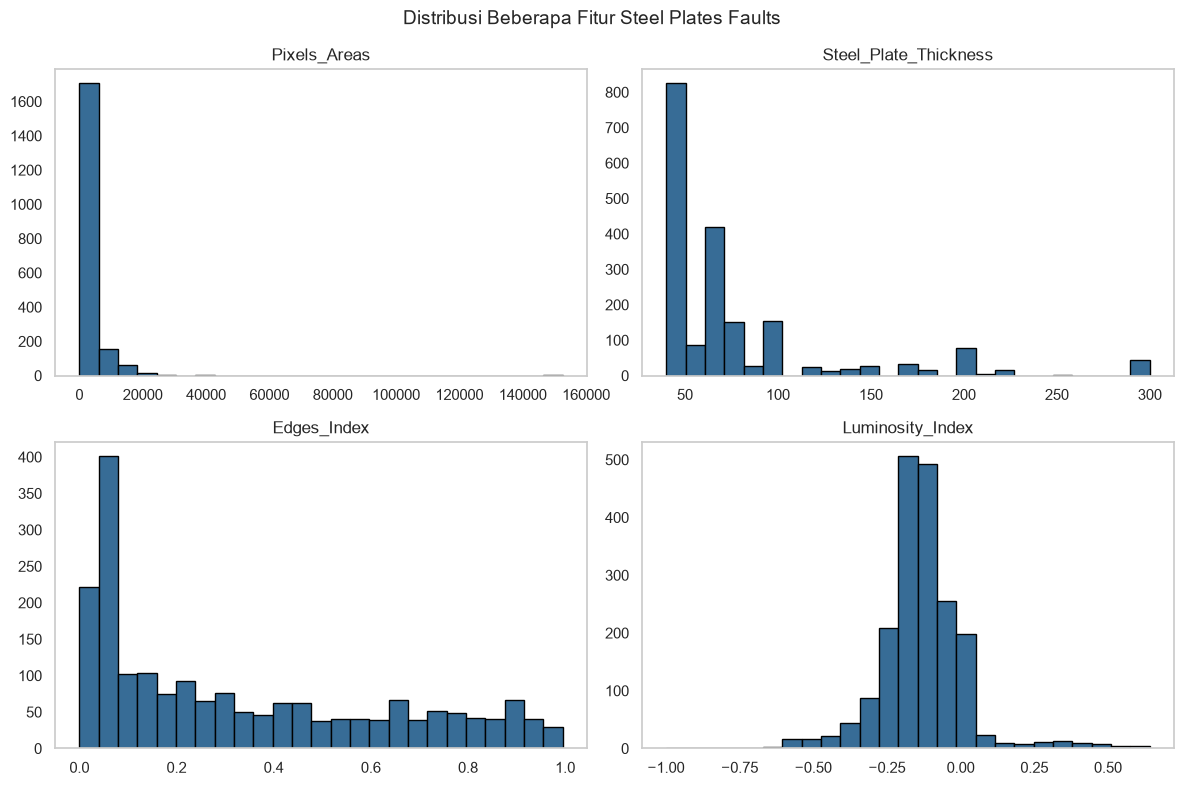

In [7]:
# CELL 7 - HISTOGRAM FITUR NUMERIK

selected_features = [
    "Pixels_Areas",
    "Steel_Plate_Thickness",
    "Edges_Index",
    "Luminosity_Index"
]

print("FITUR YANG DIVISUALISASIKAN")
print(selected_features)

X[selected_features].hist(
    bins=25,
    figsize=(12, 8),
    layout=(2, 2),
    grid=False,
    edgecolor="black",
    color="#376c96"
)

plt.suptitle(
    "Distribusi Beberapa Fitur Steel Plates Faults",
    fontsize=14
)

plt.tight_layout()
plt.show()

### Penjelasan Cell 7 — Histogram Fitur Numerik

Histogram digunakan untuk melihat pola distribusi nilai pada fitur numerik.

Pada tahap ini dipilih empat fitur sebagai contoh:

- **Pixels_Areas:** menunjukkan luas area kecacatan berdasarkan jumlah piksel.
- **Steel_Plate_Thickness:** menunjukkan ketebalan pelat baja.
- **Edges_Index:** merupakan salah satu parameter karakteristik tepi pada data kecacatan.
- **Luminosity_Index:** menggambarkan karakteristik intensitas pada citra area cacat.

Histogram membantu mengetahui apakah data terkonsentrasi pada rentang tertentu, tersebar merata, atau memiliki distribusi yang tidak simetris.

Informasi ini berguna dalam mempertimbangkan tahapan preprocessing.

Selain itu, fitur dengan nilai yang sangat berbeda atau distribusi yang miring perlu diperhatikan karena dapat memengaruhi beberapa metode analisis Machine Learning.

MATRIKS KORELASI 27 FITUR


,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,Length_of_Conveyer,TypeOfSteel_A300,TypeOfSteel_A400,Steel_Plate_Thickness,Edges_Index,Empty_Index,Square_Index,Outside_X_Index,Edges_X_Index,Edges_Y_Index,Outside_Global_Index,LogOfAreas,Log_X_Index,Log_Y_Index,Orientation_Index,Luminosity_Index,SigmoidOfAreas
X_Minimum,1.00,0.99,0.04,0.04,-0.31,-0.26,-0.12,-0.34,0.24,-0.08,0.32,0.14,-0.14,0.14,0.28,-0.20,0.06,-0.36,0.15,0.37,0.15,-0.43,-0.44,-0.33,0.18,-0.03,-0.36
X_Maximum,0.99,1.00,0.05,0.05,-0.23,-0.19,-0.09,-0.25,0.17,-0.06,0.30,0.11,-0.11,0.11,0.24,-0.15,0.05,-0.21,0.15,0.27,0.10,-0.33,-0.32,-0.27,0.12,-0.04,-0.29
Y_Minimum,0.04,0.05,1.00,1.00,0.02,0.02,0.02,0.01,-0.07,-0.07,-0.05,0.08,-0.08,-0.21,0.02,-0.04,-0.01,0.05,0.07,-0.04,-0.06,0.04,0.07,-0.01,-0.09,-0.09,0.03
Y_Maximum,0.04,0.05,1.00,1.00,0.02,0.02,0.02,0.01,-0.07,-0.07,-0.05,0.08,-0.08,-0.21,0.02,-0.04,-0.01,0.05,0.07,-0.04,-0.06,0.04,0.07,-0.01,-0.09,-0.09,0.03
Pixels_Areas,-0.31,-0.23,0.02,0.02,1.00,0.97,0.83,0.98,-0.50,0.11,-0.16,-0.24,0.24,-0.18,-0.28,0.27,0.02,0.59,-0.29,-0.46,-0.11,0.65,0.60,0.58,-0.14,-0.04,0.42
X_Perimeter,-0.26,-0.19,0.02,0.02,0.97,1.00,0.91,0.91,-0.40,0.11,-0.13,-0.19,0.19,-0.15,-0.23,0.31,0.00,0.52,-0.29,-0.41,-0.08,0.56,0.52,0.52,-0.10,-0.03,0.38
Y_Perimeter,-0.12,-0.09,0.02,0.02,0.83,0.91,1.00,0.70,-0.21,0.06,-0.06,-0.10,0.10,-0.06,-0.11,0.19,-0.05,0.21,-0.20,-0.14,0.01,0.29,0.23,0.34,0.03,-0.05,0.19
Sum_of_Luminosity,-0.34,-0.25,0.01,0.01,0.98,0.91,0.70,1.00,-0.54,0.14,-0.17,-0.26,0.26,-0.20,-0.30,0.29,0.05,0.66,-0.33,-0.53,-0.12,0.71,0.67,0.62,-0.16,-0.01,0.46
Minimum_of_Luminosity,0.24,0.17,-0.07,-0.07,-0.50,-0.40,-0.21,-0.54,1.00,0.43,-0.02,0.04,-0.04,0.10,0.36,-0.04,0.07,-0.49,0.25,0.32,0.04,-0.68,-0.57,-0.59,0.06,0.67,-0.51
Maximum_of_Luminosity,-0.08,-0.06,-0.07,-0.07,0.11,0.11,0.06,0.14,0.43,1.00,-0.10,-0.22,0.22,-0.13,0.15,0.03,0.07,0.10,0.09,-0.17,-0.12,0.01,0.09,-0.07,-0.17,0.87,-0.04


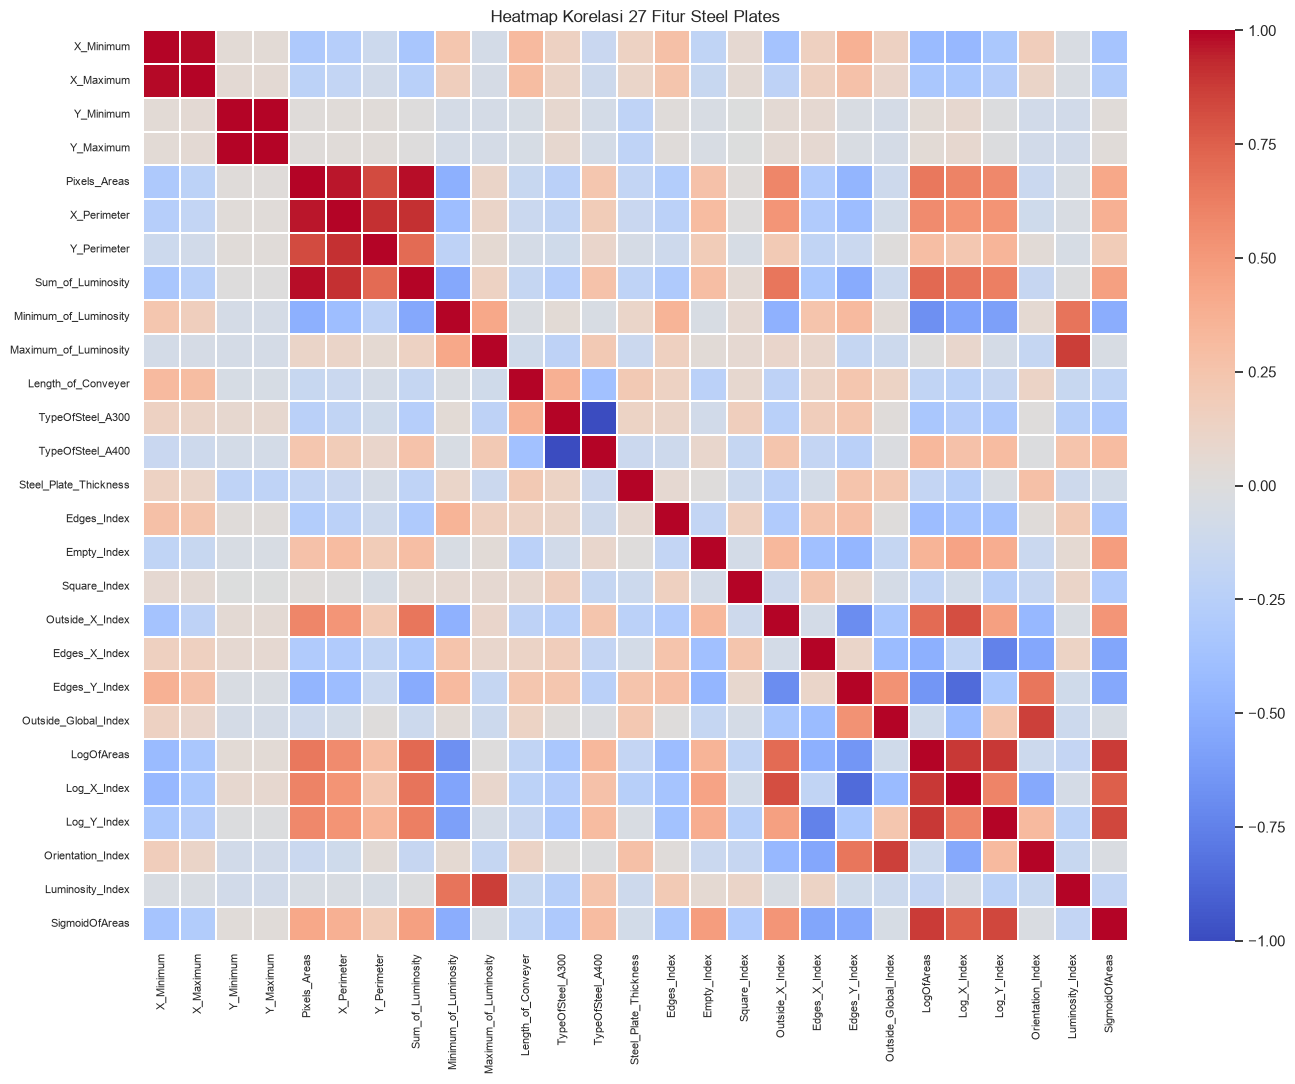

In [8]:
# CELL 8 - ANALISIS KORELASI FITUR

correlation_matrix = X.corr()

print("MATRIKS KORELASI 27 FITUR")
display(correlation_matrix.round(2))

fig, ax = plt.subplots(figsize=(14, 11))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.2,
    ax=ax
)

ax.set_title("Heatmap Korelasi 27 Fitur Steel Plates")

plt.xticks(rotation=90, fontsize=8)
plt.yticks(rotation=0, fontsize=8)

plt.tight_layout()
plt.show()

### Penjelasan Cell 8 — Analisis Korelasi

Heatmap korelasi digunakan untuk mengetahui hubungan linear antarfitur pada dataset Steel Plates Faults.

Nilai korelasi berada pada rentang -1 sampai 1.

- **Mendekati 1:** terdapat hubungan linear positif yang kuat.
- **Mendekati -1:** terdapat hubungan linear negatif yang kuat.
- **Mendekati 0:** hubungan linearnya lemah.

Hubungan positif berarti kedua fitur cenderung meningkat bersama, sedangkan hubungan negatif menunjukkan kecenderungan yang berlawanan.

Melalui heatmap ini, dapat diidentifikasi fitur yang memiliki hubungan kuat atau informasi yang sebagian berulang.

Namun, korelasi tidak membuktikan hubungan sebab-akibat. Fitur dengan korelasi tinggi juga tidak langsung dihapus karena masih perlu diuji pengaruhnya terhadap performa model.

In [9]:
# CELL 9 - ANALISIS KORELASI TINGGI

correlation = X.corr()

# Mengambil segitiga atas matriks korelasi
upper_mask = np.triu(
    np.ones(correlation.shape, dtype=bool),
    k=1
)

upper_corr = correlation.where(upper_mask)

# Membentuk daftar pasangan fitur
correlation_pairs = (
    upper_corr.stack()
    .reset_index()
)

correlation_pairs.columns = [
    "Fitur_1",
    "Fitur_2",
    "Korelasi"
]

correlation_pairs["Korelasi_Absolut"] = (
    correlation_pairs["Korelasi"].abs()
)

correlation_pairs = correlation_pairs.sort_values(
    "Korelasi_Absolut",
    ascending=False
).reset_index(drop=True)

print("12 PASANGAN FITUR DENGAN KORELASI TERTINGGI")
display(correlation_pairs.head(12).round(4))

# Mengidentifikasi fitur berkorelasi sangat kuat
high_correlation = correlation_pairs[
    correlation_pairs["Korelasi_Absolut"] >= 0.90
]

print("\nJUMLAH PASANGAN DENGAN |r| >= 0.90:")
print(len(high_correlation))

display(high_correlation.round(4))

# Pemeriksaan indikator jenis baja
print("\nHUBUNGAN INDIKATOR JENIS BAJA")

display(
    X[
        ["TypeOfSteel_A300", "TypeOfSteel_A400"]
    ].drop_duplicates()
)

12 PASANGAN FITUR DENGAN KORELASI TERTINGGI


,Fitur_1,Fitur_2,Korelasi,Korelasi_Absolut
0,TypeOfSteel_A300,TypeOfSteel_A400,-1.0000,1.0000
1,Y_Minimum,Y_Maximum,1.0000,1.0000
2,X_Minimum,X_Maximum,0.9883,0.9883
3,Pixels_Areas,Sum_of_Luminosity,0.9790,0.9790
4,Pixels_Areas,X_Perimeter,0.9666,0.9666
5,X_Perimeter,Sum_of_Luminosity,0.9130,0.9130
6,X_Perimeter,Y_Perimeter,0.9124,0.9124
7,LogOfAreas,Log_X_Index,0.8889,0.8889
8,LogOfAreas,Log_Y_Index,0.8830,0.8830
9,LogOfAreas,SigmoidOfAreas,0.8778,0.8778



JUMLAH PASANGAN DENGAN |r| >= 0.90:
7


,Fitur_1,Fitur_2,Korelasi,Korelasi_Absolut
0,TypeOfSteel_A300,TypeOfSteel_A400,-1.0000,1.0000
1,Y_Minimum,Y_Maximum,1.0000,1.0000
2,X_Minimum,X_Maximum,0.9883,0.9883
3,Pixels_Areas,Sum_of_Luminosity,0.9790,0.9790
4,Pixels_Areas,X_Perimeter,0.9666,0.9666
5,X_Perimeter,Sum_of_Luminosity,0.9130,0.9130
6,X_Perimeter,Y_Perimeter,0.9124,0.9124



HUBUNGAN INDIKATOR JENIS BAJA


,TypeOfSteel_A300,TypeOfSteel_A400
0,1,0
3,0,1


### Penjelasan Cell 9 — Hubungan dan Redundansi Fitur

Pada tahap ini dilakukan identifikasi pasangan fitur yang memiliki korelasi linear paling kuat.

**Redundansi fitur** merupakan kondisi ketika beberapa fitur memiliki informasi yang sebagian sama atau saling berhubungan.

Fitur dengan korelasi tinggi dapat memberikan informasi yang mirip kepada model Machine Learning.

Analisis ini juga memeriksa hubungan antara indikator jenis baja A300 dan A400.

Tujuannya adalah memahami struktur hubungan antarfitur sebelum mempertimbangkan feature selection.

Namun, fitur yang berkorelasi tinggi tidak langsung dihapus karena keputusan pengurangan fitur perlu didasarkan pada hasil eksperimen model.

Analisis korelasi menjadi informasi awal bagi Orang 3 dan Orang 4 untuk mengevaluasi penggunaan seluruh 27 fitur dibandingkan subset fitur terpilih.

ANALISIS CLASS IMBALANCE
Kelas terbanyak : Other_Faults
Jumlah terbanyak: 673
Kelas tersedikit: Dirtiness
Jumlah tersedikit: 55
Rasio imbalance: 12.24


,Jumlah,Persentase
Pastry,158,8.14
Z_Scratch,190,9.79
K_Scatch,391,20.14
Stains,72,3.71
Dirtiness,55,2.83
Bumps,402,20.71
Other_Faults,673,34.67


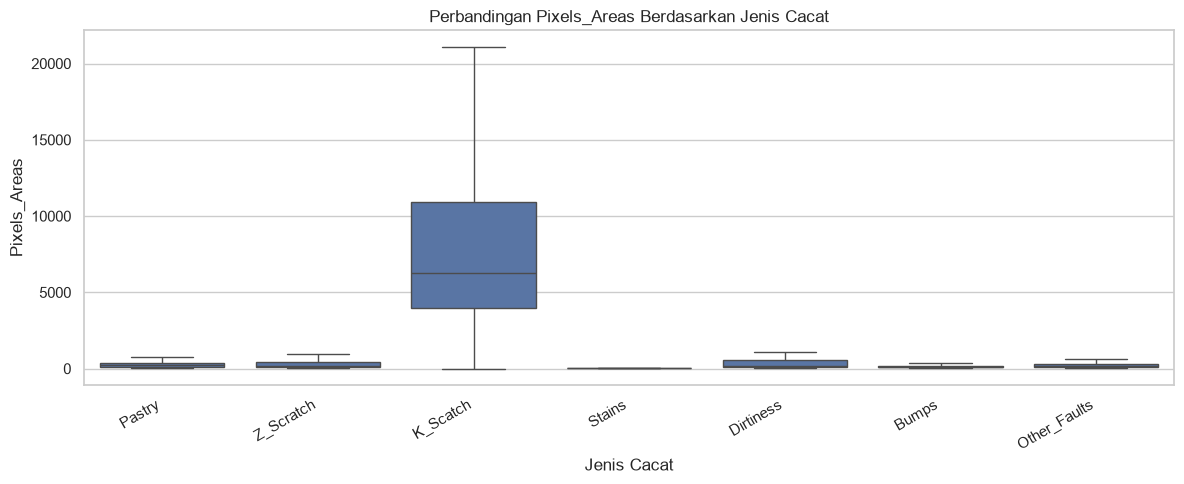

In [10]:
# CELL 10 - CLASS IMBALANCE DAN BOXPLOT

class_counts = y.value_counts().reindex(
    FAULT_TYPES,
    fill_value=0
)

positive_counts = class_counts[class_counts > 0]

imbalance_ratio = (
    positive_counts.max() / positive_counts.min()
)

print("ANALISIS CLASS IMBALANCE")
print("=" * 45)

print("Kelas terbanyak :", class_counts.idxmax())
print("Jumlah terbanyak:", int(class_counts.max()))

print("Kelas tersedikit:", positive_counts.idxmin())
print("Jumlah tersedikit:", int(positive_counts.min()))

print("Rasio imbalance:", round(imbalance_ratio, 2))

class_summary = pd.DataFrame({
    "Jumlah": class_counts,
    "Persentase": (
        class_counts / len(y) * 100
    ).round(2)
})

display(class_summary)

# Menggabungkan fitur dengan target
plot_df = pd.DataFrame({
    "Pixels_Areas": X["Pixels_Areas"],
    "Fault_Type": y
})

fig, ax = plt.subplots(figsize=(12, 5))

sns.boxplot(
    data=plot_df,
    x="Fault_Type",
    y="Pixels_Areas",
    order=FAULT_TYPES,
    showfliers=False,
    ax=ax
)

ax.set_title(
    "Perbandingan Pixels_Areas Berdasarkan Jenis Cacat"
)

ax.set_xlabel("Jenis Cacat")
ax.set_ylabel("Pixels_Areas")

plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### Penjelasan Cell 10 — Class Imbalance dan Boxplot

Pada tahap ini dilakukan pemeriksaan ketidakseimbangan kelas berdasarkan perbandingan jumlah data terbesar dan terkecil.

Rasio tersebut digunakan untuk mengetahui seberapa besar perbedaan jumlah observasi antara kelas mayoritas dan minoritas.

Selain itu, dilakukan visualisasi boxplot untuk membandingkan distribusi fitur Pixels_Areas berdasarkan tujuh jenis kecacatan.

Boxplot membantu memperlihatkan:

1. Nilai median setiap kelas.
2. Rentang nilai tengah data.
3. Perbedaan distribusi antarjenis kecacatan.

Parameter showfliers=False digunakan untuk menyembunyikan tampilan titik outlier agar grafik lebih mudah dibaca. Pengaturan tersebut tidak menghapus data dari dataset.

Jika distribusi Pixels_Areas berbeda antarkelas, fitur tersebut berpotensi berguna untuk klasifikasi.

Namun, kontribusinya terhadap prediksi tetap perlu diuji melalui pelatihan dan evaluasi model supervised learning.

In [11]:
# CELL 11 - VALIDASI PREPROCESSING

# Membagi data menjadi training dan testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

# Membuat pipeline preprocessing
preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Fit preprocessing hanya pada data training
X_train_processed = preprocessor.fit_transform(X_train)

# Data testing hanya ditransformasi
X_test_processed = preprocessor.transform(X_test)

print("VALIDASI PREPROCESSING")
print("=" * 45)

print("Data training :", X_train.shape)
print("Data testing  :", X_test.shape)

print("\nHASIL SETELAH PREPROCESSING")
print("Training:", X_train_processed.shape)
print("Testing :", X_test_processed.shape)

print("\nMISSING VALUE SETELAH PREPROCESSING")
print("Training:", np.isnan(X_train_processed).sum())
print("Testing :", np.isnan(X_test_processed).sum())

print("\nRATA-RATA FITUR TRAINING")
print(np.round(X_train_processed.mean(axis=0), 4))

print("\nSTANDAR DEVIASI FITUR TRAINING")
print(np.round(X_train_processed.std(axis=0), 4))

# Memastikan struktur data sesuai
assert X_train_processed.shape[1] == 27
assert X_test_processed.shape[1] == 27

assert np.isfinite(X_train_processed).all()
assert np.isfinite(X_test_processed).all()

print("\nVALIDASI BERHASIL")

VALIDASI PREPROCESSING
Data training : (1552, 27)
Data testing  : (389, 27)

HASIL SETELAH PREPROCESSING
Training: (1552, 27)
Testing : (389, 27)

MISSING VALUE SETELAH PREPROCESSING
Training: 0
Testing : 0

RATA-RATA FITUR TRAINING
[-0.  0.  0.  0.  0. -0. -0.  0. -0. -0.  0.  0. -0.  0. -0. -0. -0. -0.
  0.  0. -0.  0.  0.  0.  0. -0.  0.]

STANDAR DEVIASI FITUR TRAINING
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1.]

VALIDASI BERHASIL


### Penjelasan Cell 11 — Validasi Preprocessing

Preprocessing dilakukan untuk memastikan data siap digunakan dalam proses Machine Learning.

Pada tahap ini terdapat tiga proses utama.

**1. Pembagian Dataset**

Data dibagi menjadi 80% data training dan 20% data testing.

Parameter stratify=y digunakan untuk mempertahankan proporsi jenis kecacatan pada data training dan testing.

**2. Penanganan Missing Value**

SimpleImputer dengan metode median digunakan untuk mengganti nilai kosong pada fitur numerik.

**3. Standardisasi Fitur**

StandardScaler digunakan untuk mengubah skala fitur agar mempunyai rata-rata mendekati nol dan standar deviasi mendekati satu pada data training.

Preprocessing hanya di-fit menggunakan data training, sedangkan data testing hanya ditransformasi.

Langkah ini penting untuk mencegah data leakage, yaitu kondisi ketika informasi data testing ikut digunakan pada tahap pembelajaran dari data training.

Cell ini hanya memvalidasi proses preprocessing. Model klasifikasi tetap dilatih oleh Orang 3, sedangkan model clustering dikembangkan oleh Orang 4.

In [12]:
# CELL 12 - RINGKASAN HASIL EDA

summary = {
    "Jumlah Baris": len(df),
    "Jumlah Kolom Dataset": df.shape[1],
    "Jumlah Fitur": X.shape[1],
    "Jumlah Kelas": y.nunique(),
    "Missing Value": int(df.isna().sum().sum()),
    "Baris Duplikat": int(df.duplicated().sum()),
    "Korelasi Tinggi (>= 0.90)": len(high_correlation),
    "Rasio Class Imbalance": round(
        imbalance_ratio, 2
    )
}

summary_df = pd.DataFrame(
    summary.items(),
    columns=["Komponen", "Hasil"]
)

print("=" * 60)
print("RINGKASAN EDA - STEEL PLATES FAULTS")
print("=" * 60)

display(summary_df)

print("\nDISTRIBUSI LABEL")
display(class_summary)

print("\nREKOMENDASI UNTUK ORANG 3 - SUPERVISED")
print("1. Gunakan 27 fitur sebagai baseline.")
print("2. Gunakan stratified train-test split.")
print("3. Evaluasi macro F1, precision, dan recall.")
print("4. Uji feature selection pada data training.")
print("5. Jangan memasukkan 7 label sebagai fitur.")

print("\nREKOMENDASI UNTUK ORANG 4 - UNSUPERVISED")
print("1. Gunakan 27 fitur tanpa label kelas.")
print("2. Lakukan scaling sebelum clustering.")
print("3. Evaluasi Elbow dan Silhouette Score.")
print("4. Analisis profil setiap cluster.")
print("5. Gunakan PCA untuk visualisasi.")

print("\nSTATUS")
print("EDA dan validasi preprocessing selesai.")
print("Belum dilakukan training model pada notebook ini.")

RINGKASAN EDA - STEEL PLATES FAULTS


,Komponen,Hasil
0,Jumlah Baris,1941.00
1,Jumlah Kolom Dataset,34.00
2,Jumlah Fitur,27.00
3,Jumlah Kelas,7.00
4,Missing Value,0.00
5,Baris Duplikat,0.00
6,Korelasi Tinggi (>= 0.90),7.00
7,Rasio Class Imbalance,12.24



DISTRIBUSI LABEL


,Jumlah,Persentase
Pastry,158,8.14
Z_Scratch,190,9.79
K_Scatch,391,20.14
Stains,72,3.71
Dirtiness,55,2.83
Bumps,402,20.71
Other_Faults,673,34.67



REKOMENDASI UNTUK ORANG 3 - SUPERVISED
1. Gunakan 27 fitur sebagai baseline.
2. Gunakan stratified train-test split.
3. Evaluasi macro F1, precision, dan recall.
4. Uji feature selection pada data training.
5. Jangan memasukkan 7 label sebagai fitur.

REKOMENDASI UNTUK ORANG 4 - UNSUPERVISED
1. Gunakan 27 fitur tanpa label kelas.
2. Lakukan scaling sebelum clustering.
3. Evaluasi Elbow dan Silhouette Score.
4. Analisis profil setiap cluster.
5. Gunakan PCA untuk visualisasi.

STATUS
EDA dan validasi preprocessing selesai.
Belum dilakukan training model pada notebook ini.


### Penjelasan Cell 12 — Kesimpulan EDA dan Rekomendasi

Tahap terakhir merupakan ringkasan seluruh proses Exploratory Data Analysis pada dataset Steel Plates Faults.

Proses analisis yang dilakukan meliputi:

1. Pemeriksaan struktur dan statistik dataset.
2. Pemeriksaan missing value dan data duplikat.
3. Pemisahan 27 fitur dan tujuh label kecacatan.
4. Pemeriksaan distribusi kelas.
5. Visualisasi fitur numerik.
6. Analisis korelasi dan redundansi fitur.
7. Pemeriksaan class imbalance.
8. Validasi preprocessing.

**Rekomendasi untuk Orang 3 — Supervised Learning**

Dataset dapat digunakan untuk melatih model klasifikasi jenis kecacatan pelat baja.

Proses pelatihan perlu memperhatikan ketidakseimbangan kelas, pembagian data training dan testing, serta penggunaan metrik evaluasi yang tepat.

Feature selection dapat diuji untuk mengetahui apakah jumlah fitur dapat dikurangi tanpa menurunkan performa klasifikasi secara berarti.

**Rekomendasi untuk Orang 4 — Unsupervised Learning**

Clustering dilakukan menggunakan fitur input tanpa memasukkan label jenis kecacatan.

Penentuan jumlah cluster perlu dievaluasi menggunakan metode yang sesuai, seperti Elbow Method dan Silhouette Score.

Hasil cluster kemudian dianalisis berdasarkan karakteristik fiturnya dan divisualisasikan menggunakan PCA.

**Kesimpulan**

Notebook EDA digunakan untuk memahami karakteristik awal dataset dan memvalidasi persiapan data untuk Machine Learning.

Hasil analisis menjadi dasar bagi pengembangan modul supervised dan unsupervised pada proyek kelompok.

Notebook ini tidak menggantikan src/data_pipeline.py yang digunakan oleh aplikasi web.